In [1]:
%pip install torch torchvision

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import torch
import torchvision

print("PyTorch version:", torch.__version__)
print("TorchVision version:", torchvision.__version__)
print("GPU available:", torch.cuda.is_available())

PyTorch version: 2.14.1+cpu
TorchVision version: 0.29.1+cpu
GPU available: False


In [3]:
%pip install numpy pandas matplotlib seaborn scikit-learn pillow streamlit captum

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import os

print("Current working directory:")
print(os.getcwd())

print("\nFiles and folders:")
print(os.listdir("."))

Current working directory:
C:\Users\lucky\Downloads\archive (11)\chest_xray

Files and folders:
['.ipynb_checkpoints', 'chest_xray', 'Medical_Image_Classification_XAI.ipynb', 'test', 'train', 'val', '__MACOSX']


In [5]:
# datset load
from pathlib import Path

base_path = Path(".")

for folder in ["train", "test", "val"]:
    path = base_path / folder

    if path.exists():
        print(f"\n{folder.upper()}")

        for class_name in ["NORMAL", "PNEUMONIA"]:
            class_path = path / class_name

            if class_path.exists():
                images = [
                    f for f in class_path.iterdir()
                    if f.is_file()
                ]
                print(f"{class_name}: {len(images)} images")
            else:
                print(f"{class_name}: folder not found")
    else:
        print(f"{folder}: not found at {path.resolve()}")


TRAIN
NORMAL: 1341 images
PNEUMONIA: 3875 images

TEST
NORMAL: 234 images
PNEUMONIA: 390 images

VAL
NORMAL: 8 images
PNEUMONIA: 8 images


In [6]:
# Image dimensions aur color channels check
from PIL import Image

for class_name in ["NORMAL", "PNEUMONIA"]:
    folder = Path("train") / class_name

    image_path = next(
        p for p in folder.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    )

    with Image.open(image_path) as img:
        print(f"{class_name}:")
        print("  Image size:", img.size)
        print("  Image mode:", img.mode)
        print("  Format:", img.format)

NORMAL:
  Image size: (2090, 1858)
  Image mode: L
  Format: JPEG
PNEUMONIA:
  Image size: (1152, 760)
  Image mode: L
  Format: JPEG


In [7]:
# Image preprocessing aur DataLoaders
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from pathlib import Path

# Dataset path
DATA_DIR = Path.cwd()

# ImageNet pretrained DenseNet121 ke normalization values
IMAGE_SIZE = 224
BATCH_SIZE = 32

# Training transformations
train_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomRotation(5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Validation/test mein random augmentation nahi karna
eval_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=3),
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Dataset path:", DATA_DIR)

Dataset path: C:\Users\lucky\Downloads\archive (11)\chest_xray


In [8]:
# Training aur test DataLoaders banao
train_dataset = datasets.ImageFolder(
    root=DATA_DIR / "train",
    transform=train_transform
)

test_dataset = datasets.ImageFolder(
    root=DATA_DIR / "test",
    transform=eval_transform
)

print("Class mapping:", train_dataset.class_to_idx)
print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))

assert train_dataset.class_to_idx == test_dataset.class_to_idx

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("DataLoaders created successfully!")

Class mapping: {'NORMAL': 0, 'PNEUMONIA': 1}
Training images: 5216
Testing images: 624
DataLoaders created successfully!


In [9]:
# Tensor shape verify karo
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Labels shape:", labels.shape)
print("First 10 labels:", labels[:10].tolist())
print("Image tensor dtype:", images.dtype)

Image batch shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])
First 10 labels: [1, 1, 0, 1, 1, 1, 1, 1, 0, 1]
Image tensor dtype: torch.float32


In [10]:
# Training aur Validation data ready karna
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset
from torchvision import datasets
import numpy as np

# Fixed random seed: results repeat karne mein help karta hai
SEED = 42

# Training dataset ke labels
labels = np.array(train_dataset.targets)

# Sabhi image positions: 0, 1, 2, 3...
indices = np.arange(len(labels))

# 80% training aur 20% validation
train_idx, val_idx = train_test_split(
    indices,
    test_size=0.20,
    random_state=SEED,
    stratify=labels
)

# Validation images ko bina random augmentation ke load karo
eval_dataset = datasets.ImageFolder(
    root=DATA_DIR / "train",
    transform=eval_transform
)

# Dono datasets ke subsets
train_subset = Subset(train_dataset, train_idx)
val_subset = Subset(eval_dataset, val_idx)

# DataLoaders: images ko batches mein denge
train_loader = DataLoader(
    train_subset,
    batch_size=32,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_subset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

print("Training images:", len(train_subset))
print("Validation images:", len(val_subset))
print("Test images:", len(test_dataset))
print("Data preparation complete!")

Training images: 4172
Validation images: 1044
Test images: 624
Data preparation complete!


In [15]:
# Model creation

# 1. Required libraries import karna
import torch
import torch.nn as nn

from torchvision.models import (
    densenet121,
    DenseNet121_Weights
)

from sklearn.base import BaseEstimator


# 2. PyTorch model ka wrapper banana
class MedicalImageClassifier(BaseEstimator):

    # Model ke parameters define karna
    def __init__(self, num_classes=2, pretrained=True):
        self.num_classes = num_classes
        self.pretrained = pretrained

    # Actual Deep Learning model create karna
    def create_model(self):
        weights = (
            DenseNet121_Weights.DEFAULT
            if self.pretrained else None
        )

        model = densenet121(weights=weights)

        # Final layer ko 2 classes ke liye set karna
        model.classifier = nn.Linear(
            model.classifier.in_features,
            self.num_classes
        )

        return model


# 3. Classifier ka object banana
model = MedicalImageClassifier(
    num_classes=2,
    pretrained=True
)

# 4. Jupyter mein object display karna
model

,num_classes,2
,pretrained,True


In [16]:
# Actual DenseNet121 model create karna
model_dl = model.create_model()

# Model ko CPU ya GPU par set karna
model_dl = model_dl.to(device)

# Jupyter mein model ka short summary display karna
print("Deep Learning model created successfully!")
print("Architecture: DenseNet121")
print("Number of classes:", model.num_classes)
print("Class names:", train_dataset.classes)
print("Device:", device)
print("Output layer:", model_dl.classifier)

Deep Learning model created successfully!
Architecture: DenseNet121
Number of classes: 2
Class names: ['NORMAL', 'PNEUMONIA']
Device: cpu
Output layer: Linear(in_features=1024, out_features=2, bias=True)


In [17]:
# Model ko training ke liye ready karo
# Abhi model ke paas pehle se seekhe hue image features hain,
# lekin uski final layer humne NORMAL aur PNEUMONIA ke liye nayi banayi hai. 
# Pehle sirf usi final layer ko train karenge.

import torch.nn as nn

# Step 1: Feature extractor ki layers freeze karo
for param in model_dl.features.parameters():
    param.requires_grad = False

# Step 2: Loss function set karo
criterion = nn.CrossEntropyLoss()

# Step 3: Optimizer sirf final classifier ko update karega
optimizer = torch.optim.Adam(
    model_dl.classifier.parameters(),
    lr=0.001
)

# Step 4: Verify karo
trainable_params = sum(
    p.numel()
    for p in model_dl.parameters()
    if p.requires_grad
)

total_params = sum(
    p.numel()
    for p in model_dl.parameters()
)

print("Model training setup complete!")
print("Loss function:", criterion)
print("Optimizer:", optimizer.__class__.__name__)
print("Trainable parameters:", trainable_params)
print("Total parameters:", total_params)

Model training setup complete!
Loss function: CrossEntropyLoss()
Optimizer: Adam
Trainable parameters: 2050
Total parameters: 6955906


In [18]:
# Model train karo
import torch
import matplotlib.pyplot as plt

# Training history store karne ke liye
train_losses = []
val_losses = []

# 5 epochs se shuru karenge
EPOCHS = 5

for epoch in range(EPOCHS):

    # -------- TRAINING --------
    model_dl.train()

    # Frozen feature extractor ko evaluation mode mein rakho
    model_dl.features.eval()

    running_train_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Purane gradients clear karo
        optimizer.zero_grad()

        # Prediction
        outputs = model_dl(images)

        # Error calculate karo
        loss = criterion(outputs, labels)

        # Model ko improve karo
        loss.backward()
        optimizer.step()

        running_train_loss += loss.item()

    epoch_train_loss = (
        running_train_loss / len(train_loader)
    )

    # -------- VALIDATION --------
    model_dl.eval()
    running_val_loss = 0.0

    with torch.no_grad():
        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model_dl(images)
            loss = criterion(outputs, labels)

            running_val_loss += loss.item()

    epoch_val_loss = (
        running_val_loss / len(val_loader)
    )

    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)

    print(
        f"Epoch [{epoch + 1}/{EPOCHS}] | "
        f"Train Loss: {epoch_train_loss:.4f} | "
        f"Validation Loss: {epoch_val_loss:.4f}"
    )

print("\nTraining complete!")

Epoch [1/5] | Train Loss: 0.2842 | Validation Loss: 0.1640
Epoch [2/5] | Train Loss: 0.1549 | Validation Loss: 0.1378
Epoch [3/5] | Train Loss: 0.1254 | Validation Loss: 0.1189
Epoch [4/5] | Train Loss: 0.1152 | Validation Loss: 0.1141
Epoch [5/5] | Train Loss: 0.1079 | Validation Loss: 0.1041

Training complete!


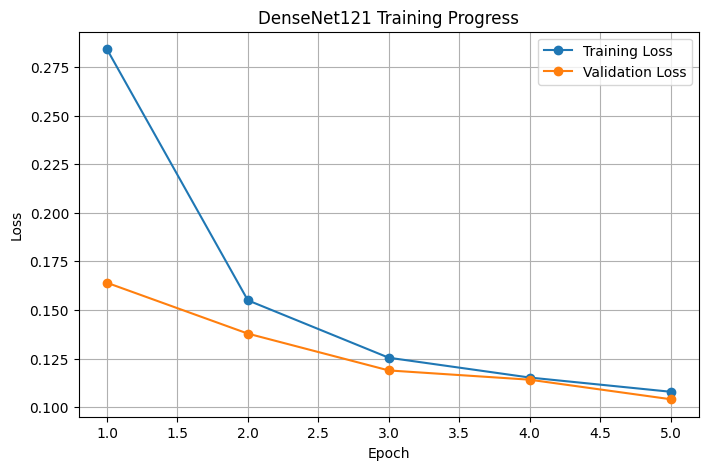

In [19]:
# Training graph dekho

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, EPOCHS + 1),
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    range(1, EPOCHS + 1),
    val_losses,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("DenseNet121 Training Progress")
plt.legend()
plt.grid(True)
plt.show()

In [20]:
# Model save karna
from pathlib import Path
import torch

# Model save karne ke liye folder
Path("models").mkdir(exist_ok=True)

# Trained model ke weights save karo
torch.save(
    model_dl.state_dict(),
    "models/densenet121_chest_xray.pth"
)

print("Model saved successfully!")
print("File: models/densenet121_chest_xray.pth")

Model saved successfully!
File: models/densenet121_chest_xray.pth


Validation Accuracy: 0.9646

Classification Report:

              precision    recall  f1-score   support

      NORMAL       0.94      0.92      0.93       268
   PNEUMONIA       0.97      0.98      0.98       776

    accuracy                           0.96      1044
   macro avg       0.96      0.95      0.95      1044
weighted avg       0.96      0.96      0.96      1044



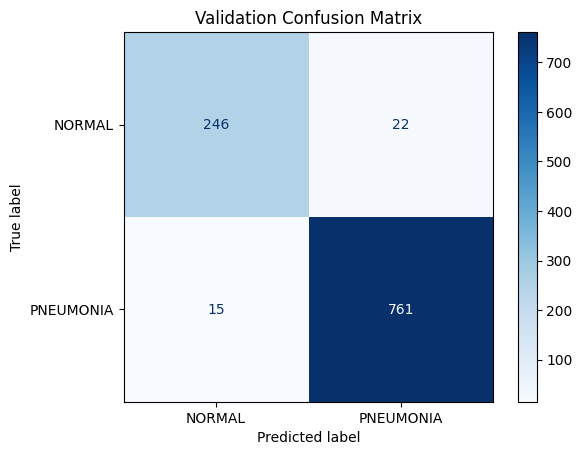

In [21]:
# Model Evaluation
# Accuracy, Precision, Recall aur F1-score
import torch
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Model ko evaluation mode mein rakho
model_dl.eval()

y_true = []
y_pred = []

# Validation images par prediction
with torch.no_grad():
    for images, labels in val_loader:

        images = images.to(device)

        outputs = model_dl(images)

        # Highest score wali class prediction hogi
        predictions = torch.argmax(outputs, dim=1)

        y_true.extend(labels.numpy())
        y_pred.extend(predictions.cpu().numpy())

# Metrics calculate karo
print("Validation Accuracy:",
      round(accuracy_score(y_true, y_pred), 4))

print("\nClassification Report:\n")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1],
    target_names=["NORMAL", "PNEUMONIA"],
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["NORMAL", "PNEUMONIA"]
)

display.plot(cmap="Blues", values_format="d")
plt.title("Validation Confusion Matrix")
plt.show()

In [ ]:
# Upar wala Grad-CAM code ye check karta hai ki hamara AI model X-ray ko dekhkar prediction karte waqt image ke kis hisse par zyada dhyan de raha hai.
# Maan lo tumne ek chest X-ray di. Ab code 4 kaam karta hai:
# 1. X-ray image leta hai: test/PNEUMONIA folder se ek image select karta hai.
# 2. Prediction karta hai: Hamara trained DenseNet121 batata hai ki image NORMAL hai ya PNEUMONIA.
# 3. Heatmap banata hai: Image ke un areas ko color se highlight karta hai jinhone model ki prediction mein zyada contribution diya.
# 4. Result dikhata hai: Original X-ray, colored heatmap aur dono ko mila kar ek image dikhata hai.

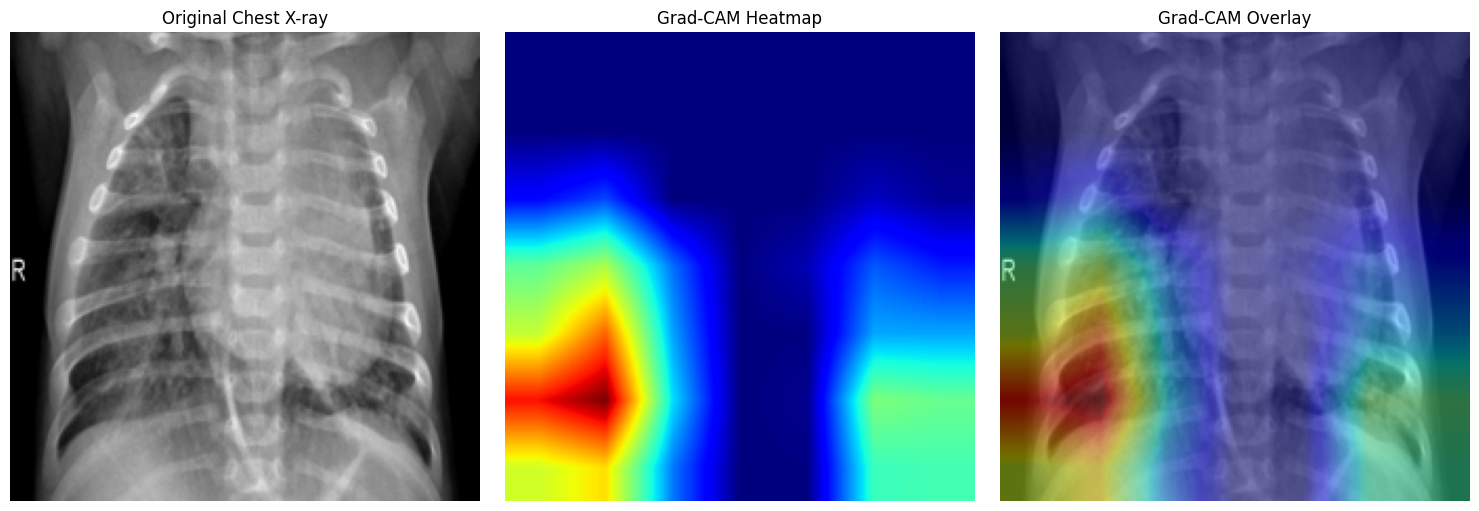

Image: person100_bacteria_475.jpeg
Predicted class: PNEUMONIA
Confidence: 96.59%


In [25]:

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from pathlib import Path
from torchvision import transforms

# Model evaluation mode
model_dl.eval()

# Test image select karo
image_path = next(
    Path("test/PNEUMONIA").glob("*.jpeg"),
    None
)

if image_path is None:
    image_path = next(Path("test/PNEUMONIA").glob("*.jpg"), None)

if image_path is None:
    raise FileNotFoundError(
        "Test/PNEUMONIA folder mein JPEG image nahi mili."
    )

# Image preprocess
image = Image.open(image_path).convert("RGB")

eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

image_tensor = eval_transform(image).unsqueeze(0).to(device)

# IMPORTANT FIX: input par gradients enable karo
image_tensor = image_tensor.detach().requires_grad_(True)

activations = []
gradients = []

# DenseNet121 ka last dense block
target_layer = model_dl.features.denseblock4

def forward_hook(module, inputs, output):
    activations.append(output)
    output.register_hook(
        lambda grad: gradients.append(grad)
    )

handle = target_layer.register_forward_hook(forward_hook)

try:
    model_dl.zero_grad(set_to_none=True)

    # Ensure gradients are enabled
    with torch.enable_grad():
        output = model_dl(image_tensor)

        probabilities = torch.softmax(output, dim=1)
        predicted_class = output.argmax(dim=1).item()
        confidence = probabilities[0, predicted_class].item()

        output[0, predicted_class].backward()

finally:
    handle.remove()

# Check that Grad-CAM data was captured
if not activations or not gradients:
    raise RuntimeError(
        "Gradients abhi bhi nahi mile. "
        "Check karo ki model_dl actual DenseNet121 model hai "
        "aur inference_mode active nahi hai."
    )

# Calculate Grad-CAM
activation = activations[0]
gradient = gradients[0]

weights = gradient.mean(dim=(2, 3), keepdim=True)
cam = (weights * activation).sum(dim=1, keepdim=True)
cam = F.relu(cam)

cam = F.interpolate(
    cam,
    size=(224, 224),
    mode="bilinear",
    align_corners=False
)

cam = cam[0, 0].detach().cpu().numpy()
cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

# Display original image, heatmap and overlay
original = np.array(image.resize((224, 224)))
heatmap = plt.get_cmap("jet")(cam)[:, :, :3]
heatmap = (heatmap * 255).astype(np.uint8)

overlay = (
    0.55 * original.astype(float) +
    0.45 * heatmap.astype(float)
).clip(0, 255).astype(np.uint8)

class_names = ["NORMAL", "PNEUMONIA"]

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original)
plt.title("Original Chest X-ray")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cam, cmap="jet")
plt.title("Grad-CAM Heatmap")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title("Grad-CAM Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

print("Image:", image_path.name)
print("Predicted class:", class_names[predicted_class])
print(f"Confidence: {confidence:.2%}")


Test Accuracy: 0.7981 (79.81%)

Classification Report:

              precision    recall  f1-score   support

      NORMAL       0.97      0.47      0.64       234
   PNEUMONIA       0.76      0.99      0.86       390

    accuracy                           0.80       624
   macro avg       0.87      0.73      0.75       624
weighted avg       0.84      0.80      0.78       624



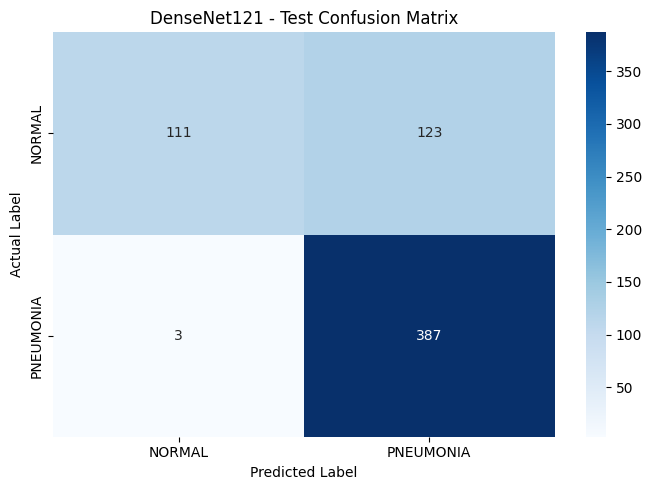

In [26]:
# Test Dataset Evaluatio

import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Model evaluation mode
model_dl.eval()

all_labels = []
all_predictions = []

# Test dataset par evaluation
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model_dl(images)
        predictions = torch.argmax(outputs, dim=1)

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predictions.cpu().numpy())

# Calculate accuracy
accuracy = accuracy_score(all_labels, all_predictions)

print(f"Test Accuracy: {accuracy:.4f} ({accuracy * 100:.2f}%)")

# Classification report
class_names = ["NORMAL", "PNEUMONIA"]

print("\nClassification Report:\n")
print(classification_report(
    all_labels,
    all_predictions,
    labels=[0, 1],
    target_names=class_names,
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(all_labels, all_predictions, labels=[0, 1])

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("DenseNet121 - Test Confusion Matrix")
plt.tight_layout()
plt.show()


In [27]:

print("Class mapping:", train_dataset.class_to_idx)
print("Train images:", len(train_dataset))
print("Test images:", len(test_dataset))

print("\nTrain transform:")
print(train_dataset.transform)

print("\nTest transform:")
print(test_dataset.transform)

print("\nModel device:", next(model_dl.parameters()).device)
print("Evaluation mode:", not model_dl.training)


Class mapping: {'NORMAL': 0, 'PNEUMONIA': 1}
Train images: 5216
Test images: 624

Train transform:
Compose(
    Grayscale(num_output_channels=3)
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    RandomRotation(degrees=[-5.0, 5.0], interpolation=nearest, expand=False, fill=0)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

Test transform:
Compose(
    Grayscale(num_output_channels=3)
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

Model device: cpu
Evaluation mode: True


In [28]:
# Train aur test class distribution compare karo

In [29]:

from collections import Counter

train_counts = Counter(train_dataset.targets)
test_counts = Counter(test_dataset.targets)

print("Class Distribution")
print("-" * 40)

for class_name, class_idx in train_dataset.class_to_idx.items():
    print(
        f"{class_name:12} | "
        f"Train: {train_counts[class_idx]:4} | "
        f"Test: {test_counts[class_idx]:4}"
    )


Class Distribution
----------------------------------------
NORMAL       | Train: 1341 | Test:  234
PNEUMONIA    | Train: 3875 | Test:  390


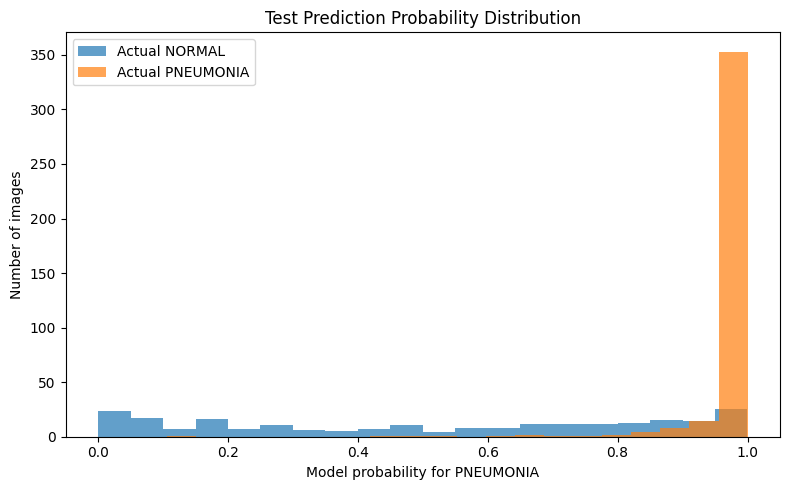

Mean pneumonia probability for NORMAL: 0.5186
Mean pneumonia probability for PNEUMONIA: 0.9779


In [30]:
# Test set par prediction probabilities check karo

import torch
import numpy as np
import matplotlib.pyplot as plt

model_dl.eval()

normal_probs = []
pneumonia_probs = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model_dl(images)
        probs = torch.softmax(outputs, dim=1).cpu().numpy()

        for label, prob in zip(labels.numpy(), probs):
            if label == 0:
                normal_probs.append(prob[1])  # P(PNEUMONIA)
            else:
                pneumonia_probs.append(prob[1])

plt.figure(figsize=(8, 5))

plt.hist(
    normal_probs,
    bins=20,
    alpha=0.7,
    label="Actual NORMAL"
)

plt.hist(
    pneumonia_probs,
    bins=20,
    alpha=0.7,
    label="Actual PNEUMONIA"
)

plt.xlabel("Model probability for PNEUMONIA")
plt.ylabel("Number of images")
plt.title("Test Prediction Probability Distribution")
plt.legend()
plt.tight_layout()
plt.show()

print("Mean pneumonia probability for NORMAL:",
      round(float(np.mean(normal_probs)), 4))

print("Mean pneumonia probability for PNEUMONIA:",
      round(float(np.mean(pneumonia_probs)), 4))


In [31]:

import copy
import torch
import torch.nn as nn

# Current model ka backup
best_model_state = copy.deepcopy(model_dl.state_dict())

# Pehle saare feature layers freeze rakho
for param in model_dl.features.parameters():
    param.requires_grad = False

# Last dense block ko unfreeze karo
for param in model_dl.features.denseblock4.parameters():
    param.requires_grad = True

for param in model_dl.features.norm5.parameters():
    param.requires_grad = True

# Classifier trainable rakho
for param in model_dl.classifier.parameters():
    param.requires_grad = True

# Small learning rates: pretrained weights ko carefully update karne ke liye
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam([
    {
        "params": model_dl.features.denseblock4.parameters(),
        "lr": 1e-5
    },
    {
        "params": model_dl.features.norm5.parameters(),
        "lr": 1e-5
    },
    {
        "params": model_dl.classifier.parameters(),
        "lr": 1e-4
    }
])

print("Fine-tuning setup ready!")
print("Trainable layers: denseblock4, norm5, classifier")


Task was destroyed but it is pending!
task: <Task pending name='Task-164' coro=<_async_in_context.<locals>.run_in_context_pre311() done, defined at C:\Users\lucky\AppData\Local\Programs\Python\Python310\lib\site-packages\ipykernel\utils.py:76> wait_for=<Task pending name='Task-165' coro=<_async_in_context.<locals>.preserve_context() running at C:\Users\lucky\AppData\Local\Programs\Python\Python310\lib\site-packages\ipykernel\utils.py:68> cb=[Task.task_wakeup()]> cb=[ZMQStream._run_callback.<locals>._log_error() at C:\Users\lucky\AppData\Local\Programs\Python\Python310\lib\site-packages\zmq\eventloop\zmqstream.py:563]>
C:\Users\lucky\AppData\Local\Programs\Python\Python310\lib\site-packages\torch\nn\modules\module.py:2166: RuntimeWarning: coroutine '_async_in_context.<locals>.preserve_context' was never awaited
  for name, buf in self._buffers.items():
Task was destroyed but it is pending!
task: <Task pending name='Task-165' coro=<_async_in_context.<locals>.preserve_context() running at

Fine-tuning setup ready!
Trainable layers: denseblock4, norm5, classifier


In [32]:
# Fine-tuning training

In [33]:

import copy
import torch
import matplotlib.pyplot as plt

EPOCHS = 3
best_val_loss = float("inf")
best_model_state = copy.deepcopy(model_dl.state_dict())

train_losses = []
val_losses = []
train_accuracies = []
val_accuracies = []

for epoch in range(EPOCHS):

    # Training
    model_dl.train()

    # Frozen feature layers ko evaluation mode mein rakho
    model_dl.features.denseblock1.eval()
    model_dl.features.denseblock2.eval()
    model_dl.features.denseblock3.eval()
    model_dl.features.transition1.eval()
    model_dl.features.transition2.eval()
    model_dl.features.transition3.eval()
    model_dl.features.conv0.eval()
    model_dl.features.norm0.eval()

    running_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad(set_to_none=True)

        outputs = model_dl(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)
        train_correct += (outputs.argmax(1) == labels).sum().item()
        train_total += labels.size(0)

    epoch_train_loss = running_loss / train_total
    epoch_train_acc = train_correct / train_total

    # Validation
    model_dl.eval()
    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model_dl(images)
            loss = criterion(outputs, labels)

            val_loss_sum += loss.item() * images.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()
            val_total += labels.size(0)

    epoch_val_loss = val_loss_sum / val_total
    epoch_val_acc = val_correct / val_total

    train_losses.append(epoch_train_loss)
    val_losses.append(epoch_val_loss)
    train_accuracies.append(epoch_train_acc)
    val_accuracies.append(epoch_val_acc)

    # Best validation-loss model save karo
    if epoch_val_loss < best_val_loss:
        best_val_loss = epoch_val_loss
        best_model_state = copy.deepcopy(model_dl.state_dict())
        torch.save(best_model_state, "models/densenet121_chest_xray_finetuned.pth")

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Train Loss: {epoch_train_loss:.4f} | "
        f"Train Acc: {epoch_train_acc:.2%} | "
        f"Val Loss: {epoch_val_loss:.4f} | "
        f"Val Acc: {epoch_val_acc:.2%}"
    )

# Best validation model restore karo
model_dl.load_state_dict(best_model_state)

print("\nFine-tuning complete!")
print("Best validation loss:", round(best_val_loss, 4))


Epoch [1/3] Train Loss: 0.1250 | Train Acc: 94.87% | Val Loss: 0.1131 | Val Acc: 95.11%
Epoch [2/3] Train Loss: 0.0933 | Train Acc: 96.09% | Val Loss: 0.1005 | Val Acc: 95.69%
Epoch [3/3] Train Loss: 0.0792 | Train Acc: 96.86% | Val Loss: 0.0920 | Val Acc: 95.98%

Fine-tuning complete!
Best validation loss: 0.092


Fine-tuned Test Accuracy: 79.81%

Classification Report:

              precision    recall  f1-score   support

      NORMAL       0.99      0.47      0.63       234
   PNEUMONIA       0.76      1.00      0.86       390

    accuracy                           0.80       624
   macro avg       0.87      0.73      0.75       624
weighted avg       0.84      0.80      0.78       624



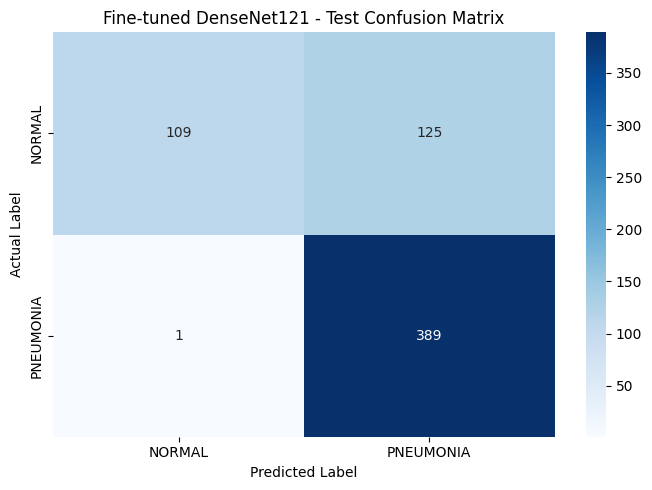

In [34]:
# Fine-tuned model ka test evaluation

import torch
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
import matplotlib.pyplot as plt
import seaborn as sns

# Best fine-tuned weights load karo
model_dl.load_state_dict(
    torch.load(
        "models/densenet121_chest_xray_finetuned.pth",
        map_location=device,
        weights_only=True
    )
)

model_dl.eval()

all_labels = []
all_predictions = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model_dl(images)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predictions.cpu().numpy())

# Metrics
test_accuracy = accuracy_score(all_labels, all_predictions)

print(f"Fine-tuned Test Accuracy: {test_accuracy:.2%}")
print("\nClassification Report:\n")

print(classification_report(
    all_labels,
    all_predictions,
    labels=[0, 1],
    target_names=["NORMAL", "PNEUMONIA"],
    zero_division=0
))

# Confusion matrix
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=[0, 1]
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["NORMAL", "PNEUMONIA"],
    yticklabels=["NORMAL", "PNEUMONIA"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Fine-tuned DenseNet121 - Test Confusion Matrix")
plt.tight_layout()
plt.show()


In [36]:

# Validation dataset ka original dataset access karo
val_base_dataset = val_loader.dataset

while hasattr(val_base_dataset, "dataset"):
    val_base_dataset = val_base_dataset.dataset

print("Validation transform:")
print(val_base_dataset.transform)

print("\nTest transform:")
print(test_dataset.transform)

print("\nClass mapping:")
print(train_dataset.class_to_idx)

print("\nValidation dataset size:", len(val_loader.dataset))
print("Test dataset size:", len(test_dataset))

print("\nModel evaluation mode:", not model_dl.training)


Validation transform:
Compose(
    Grayscale(num_output_channels=3)
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

Test transform:
Compose(
    Grayscale(num_output_channels=3)
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

Class mapping:
{'NORMAL': 0, 'PNEUMONIA': 1}

Validation dataset size: 1044
Test dataset size: 624

Model evaluation mode: True


In [37]:

import torch
from sklearn.metrics import accuracy_score, classification_report

def evaluate_model(model, loader, dataset_name):
    model.eval()
    labels_all = []
    preds_all = []

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            outputs = model(images)
            preds = outputs.argmax(dim=1)

            labels_all.extend(labels.numpy())
            preds_all.extend(preds.cpu().numpy())

    print(f"\n{'='*45}")
    print(dataset_name)
    print(f"{'='*45}")
    print(f"Accuracy: {accuracy_score(labels_all, preds_all):.2%}")
    print(classification_report(
        labels_all,
        preds_all,
        labels=[0, 1],
        target_names=["NORMAL", "PNEUMONIA"],
        zero_division=0
    ))

# Current fine-tuned weights on both datasets
evaluate_model(model_dl, val_loader, "Validation Results")
evaluate_model(model_dl, test_loader, "Test Results")



Validation Results
Accuracy: 95.98%
              precision    recall  f1-score   support

      NORMAL       0.93      0.91      0.92       268
   PNEUMONIA       0.97      0.98      0.97       776

    accuracy                           0.96      1044
   macro avg       0.95      0.94      0.95      1044
weighted avg       0.96      0.96      0.96      1044


Test Results
Accuracy: 79.81%
              precision    recall  f1-score   support

      NORMAL       0.99      0.47      0.63       234
   PNEUMONIA       0.76      1.00      0.86       390

    accuracy                           0.80       624
   macro avg       0.87      0.73      0.75       624
weighted avg       0.84      0.80      0.78       624



In [39]:

from pathlib import Path
from collections import Counter

# Original training image paths
train_paths = {
    str(Path(p).resolve())
    for p, _ in train_dataset.samples
}

# Validation subset ke original image paths
val_base = val_loader.dataset
while hasattr(val_base, "dataset"):
    val_base = val_base.dataset

val_paths = {
    str(Path(p).resolve())
    for p, _ in val_base.samples
}

print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))
print("Same file paths:", len(train_paths & val_paths))


Training images: 5216
Validation images: 5216
Same file paths: 5216


In [40]:

from pathlib import Path

# Actual training image paths
train_paths = {
    str(Path(p).resolve())
    for p, _ in train_dataset.samples
}

# Validation subset ke sirf selected indices
val_subset = val_loader.dataset

while hasattr(val_subset, "indices") is False and hasattr(val_subset, "dataset"):
    val_subset = val_subset.dataset

if hasattr(val_subset, "indices"):
    base_dataset = val_subset.dataset
    val_indices = val_subset.indices

    val_paths = {
        str(Path(base_dataset.samples[i][0]).resolve())
        for i in val_indices
    }
else:
    raise ValueError("Validation Subset nahi mila; val_loader setup check karo.")

print("Training images:", len(train_paths))
print("Validation images:", len(val_paths))
print("Shared file paths:", len(train_paths & val_paths))


Training images: 5216
Validation images: 1044
Shared file paths: 1044


In [43]:

import torch

model_dl.eval()
wrong_images = []

# test_dataset.samples mein (filepath, class_index) hota hai
with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model_dl(images)
        probs = torch.softmax(outputs, dim=1)
        preds = outputs.argmax(dim=1).cpu()

        # Labels aur predictions compare karo
        for i in range(len(labels)):
            true_label = labels[i].item()
            predicted_label = preds[i].item()

            if true_label != predicted_label:
                wrong_images.append({
                    "true_label": test_dataset.classes[true_label],
                    "predicted_label": test_dataset.classes[predicted_label],
                    "confidence": round(
                        probs[i, predicted_label].item() * 100, 2
                    )
                })

print("Total misclassified images:", len(wrong_images))
print("\nFirst 10 misclassifications:")

for item in wrong_images[:10]:
    print(item)


Total misclassified images: 126

First 10 misclassifications:
{'true_label': 'NORMAL', 'predicted_label': 'PNEUMONIA', 'confidence': 78.61}
{'true_label': 'NORMAL', 'predicted_label': 'PNEUMONIA', 'confidence': 68.69}
{'true_label': 'NORMAL', 'predicted_label': 'PNEUMONIA', 'confidence': 67.3}
{'true_label': 'NORMAL', 'predicted_label': 'PNEUMONIA', 'confidence': 85.69}
{'true_label': 'NORMAL', 'predicted_label': 'PNEUMONIA', 'confidence': 96.79}
{'true_label': 'NORMAL', 'predicted_label': 'PNEUMONIA', 'confidence': 83.31}
{'true_label': 'NORMAL', 'predicted_label': 'PNEUMONIA', 'confidence': 58.25}
{'true_label': 'NORMAL', 'predicted_label': 'PNEUMONIA', 'confidence': 83.91}
{'true_label': 'NORMAL', 'predicted_label': 'PNEUMONIA', 'confidence': 85.7}
{'true_label': 'NORMAL', 'predicted_label': 'PNEUMONIA', 'confidence': 100.0}


In [44]:

import torch

model_dl.eval()
misclassified = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(device)
        outputs = model_dl(images)
        probs = torch.softmax(outputs, dim=1)
        preds = outputs.argmax(dim=1).cpu()

        for i in range(len(labels)):
            true_label = labels[i].item()
            pred_label = preds[i].item()

            if true_label != pred_label:
                misclassified.append({
                    "true": test_dataset.classes[true_label],
                    "predicted": test_dataset.classes[pred_label],
                    "confidence": round(
                        probs[i, pred_label].item() * 100, 2
                    )
                })

print("Total errors:", len(misclassified))
print("First 10 errors:")
for item in misclassified[:10]:
    print(item)


Total errors: 126
First 10 errors:
{'true': 'NORMAL', 'predicted': 'PNEUMONIA', 'confidence': 78.61}
{'true': 'NORMAL', 'predicted': 'PNEUMONIA', 'confidence': 68.69}
{'true': 'NORMAL', 'predicted': 'PNEUMONIA', 'confidence': 67.3}
{'true': 'NORMAL', 'predicted': 'PNEUMONIA', 'confidence': 85.69}
{'true': 'NORMAL', 'predicted': 'PNEUMONIA', 'confidence': 96.79}
{'true': 'NORMAL', 'predicted': 'PNEUMONIA', 'confidence': 83.31}
{'true': 'NORMAL', 'predicted': 'PNEUMONIA', 'confidence': 58.25}
{'true': 'NORMAL', 'predicted': 'PNEUMONIA', 'confidence': 83.91}
{'true': 'NORMAL', 'predicted': 'PNEUMONIA', 'confidence': 85.7}
{'true': 'NORMAL', 'predicted': 'PNEUMONIA', 'confidence': 100.0}


In [45]:
# Model file check karo
from pathlib import Path

model_path = Path("models/densenet121_chest_xray_finetuned.pth")

print("Model file exists:", model_path.exists())
print("Model path:", model_path.resolve())

Model file exists: True
Model path: C:\Users\lucky\Downloads\archive (11)\chest_xray\models\densenet121_chest_xray_finetuned.pth


In [1]:
# for file compression
import torch

model_path = "models/densenet121_chest_xray_finetuned.pth"

state_dict = torch.load(
    model_path,
    map_location="cpu",
    weights_only=True
)

torch.save(
    state_dict,
    "models/densenet121_chest_xray_finetuned.zip.pth",
    _use_new_zipfile_serialization=True
)

In [1]:

!pip install gdown

import gdown
import os

file_id = "1D39y4yAUYJ1COTmBiSJ7RcvBLucKg_ED"

os.makedirs("models", exist_ok=True)

url = f"https://drive.google.com/uc?id={file_id}"

output = "models/densenet121_chest_xray_finetuned.pth"

gdown.download(url, output, quiet=False)

print("Downloaded:", os.path.exists(output))
if os.path.exists(output):
    print("File size:", round(os.path.getsize(output) / (1024 * 1024), 2), "MB")



[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip



   ---------------------------------------- 2/2 [gdown]



Downloading...
From (original): https://drive.google.com/uc?id=1D39y4yAUYJ1COTmBiSJ7RcvBLucKg_ED
From (redirected): https://drive.google.com/uc?id=1D39y4yAUYJ1COTmBiSJ7RcvBLucKg_ED&confirm=t&uuid=47fda638-09b1-4ef6-b725-54dcada0ab90
To: C:\Users\lucky\Downloads\archive (11)\chest-xray-pneumonia-classification-gradcam\models\densenet121_chest_xray_finetuned.pth
100%|██████████| 28.4M/28.4M [00:06<00:00, 4.69MB/s]


Downloaded: True
File size: 27.12 MB
